# IT5092 Lab 04 — Hodgkin–Huxley vs Leaky Integrate-and-Fire

**Goal:** Implement and compare a reduced neuron model (LIF) with a biophysical conductance-based neuron model (Hodgkin–Huxley).

**You will produce:**
1. LIF baseline + **F–I curve**
2. HH baseline waveform + **gating variables**
3. HH **refractory pulse-gap-pulse** experiment
4. Short comparison paragraph (HH vs LIF)

In [1]:
#Import config + build time axis

import numpy as np
from config import DT, T_TOTAL
from config import REFRAC_MS, V_TH, V_REST, R_M, TAU_M   # used later for the F–I analysis
t = np.arange(0, T_TOTAL+DT, DT)
print("DT (ms):", DT, "| T_TOTAL (ms):", T_TOTAL, "| Samples:", len(t))

DT (ms): 0.01 | T_TOTAL (ms): 80.0 | Samples: 8001


## Part A — Input current and LIF baseline
We start with a simple step current `I(t)` and simulate a Leaky Integrate-and-Fire neuron.

- LIF integrates membrane potential using a **first-order ODE**
- When the voltage crosses threshold, it is **reset**
- A **refractory period** prevents immediate re-spiking (you will implement this in `lif.py`)

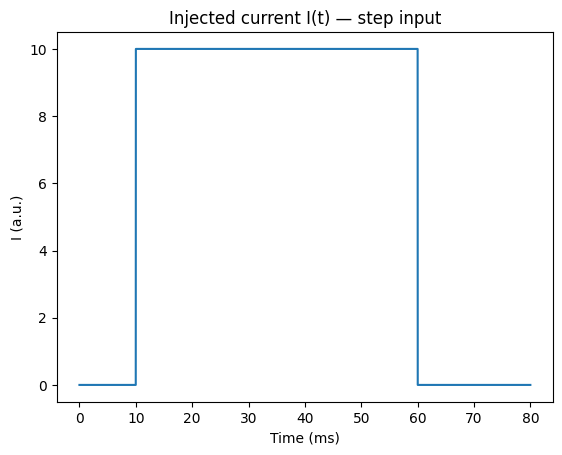

In [2]:
#Build the baseline injected current
import matplotlib.pyplot as plt

from models.input_current import step_current
I = step_current(t, t_on=10, t_off=60, amp=10)

plt.figure()
plt.plot(t, I)
plt.title("Injected current I(t) — step input")
plt.xlabel("Time (ms)")
plt.ylabel("I (a.u.)")
plt.show()

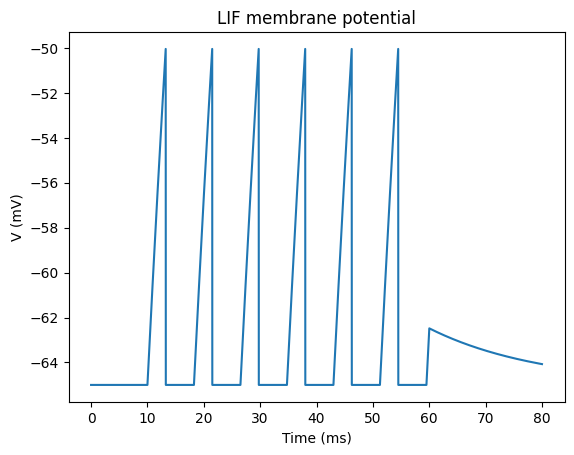

LIF spikes: 6 Rate(Hz): 75.0


In [3]:
#Run LIF baseline
# NOTE: This will fully work only after you complete TODO 1 in models/lif.py

from models.lif import simulate_lif
from utils.plotting import plot_trace
from utils.metrics import firing_rate

V_lif, sp_lif = simulate_lif(I, t)
plot_trace(t, V_lif, "LIF membrane potential", "V (mV)")
print("LIF spikes:", len(sp_lif), "Rate(Hz):", firing_rate(sp_lif, 0, T_TOTAL))

### TODO 5 — LIF F–I curve (in this notebook)

**Goal:** Show how firing rate increases as injected current increases.  
**What you do:**
1. Sweep current amplitude values
2. Run `simulate_lif(...)` for each amplitude
3. Compute firing rate in the *stimulus window* (10–60 ms)
4. Plot firing rate vs amplitude


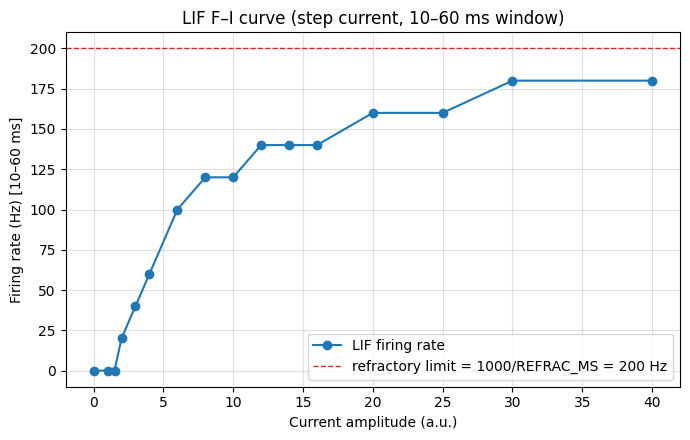

amps : [0, 1, 1.5, 2, 3, 4, 6, 8, 10, 12, 14, 16, 20, 25, 30, 40]
rates: [0.0, 0.0, 0.0, 20.0, 40.0, 60.0, 100.0, 120.0, 120.0, 140.0, 140.0, 140.0, 160.0, 160.0, 180.0, 180.0]
Approximate rheobase (a.u.): 2
Analytical rheobase (V_TH - V_REST)/R_M = 1.5


In [4]:
# Cell 5 — TODO 5 (COMPLETED): LIF F–I curve
# Sweep the injected current amplitude, run the LIF model for each amplitude and
# measure the firing rate inside the stimulation window (10–60 ms) only.

# Denser / wider sweep than the default so that both the rheobase (the smallest
# current that makes the neuron fire at all) and the refractory-limited
# saturation at high current are visible.
amps = [0, 1, 1.5, 2, 3, 4, 6, 8, 10, 12, 14, 16, 20, 25, 30, 40]
rates = []

for amp in amps:
    I_amp = step_current(t, t_on=10.0, t_off=60.0, amp=amp)
    V_tmp, sp_tmp = simulate_lif(I_amp, t)
    rate_hz = firing_rate(sp_tmp, 10.0, 60.0)  # stim window only
    rates.append(rate_hz)

# Theoretical maximum rate imposed by the 5 ms absolute refractory period
max_rate = 1000.0 / REFRAC_MS

plt.figure(figsize=(7, 4.5))
plt.plot(amps, rates, marker="o", color="tab:blue", label="LIF firing rate")
plt.axhline(max_rate, color="tab:red", ls="--", lw=1,
            label=f"refractory limit = 1000/REFRAC_MS = {max_rate:.0f} Hz")
plt.title("LIF F–I curve (step current, 10–60 ms window)")
plt.xlabel("Current amplitude (a.u.)")
plt.ylabel("Firing rate (Hz) [10–60 ms]")
plt.grid(True, alpha=0.4)
plt.legend()
plt.tight_layout()
plt.show()

print("amps :", amps)
print("rates:", rates)

# Rheobase = smallest tested amplitude that produced at least one spike
firing = [a for a, r in zip(amps, rates) if r > 0]
print("Approximate rheobase (a.u.):", firing[0] if firing else "no spiking in sweep")
print("Analytical rheobase (V_TH - V_REST)/R_M =", (V_TH - V_REST) / R_M)

## Part B — Hodgkin–Huxley (HH) baseline

HH is a **conductance-based** neuron model:
- Voltage changes due to ionic currents (Na⁺, K⁺, leak)
- Gating variables (m, h, n) control channel opening/closing
- More biologically realistic than LIF, but computationally heavier

> Your HH model will run only after you complete **TODO 2–4** in `models/hodgkin_huxley.py`.


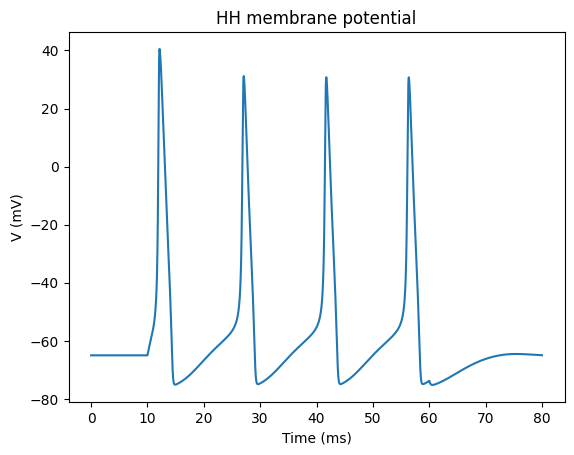

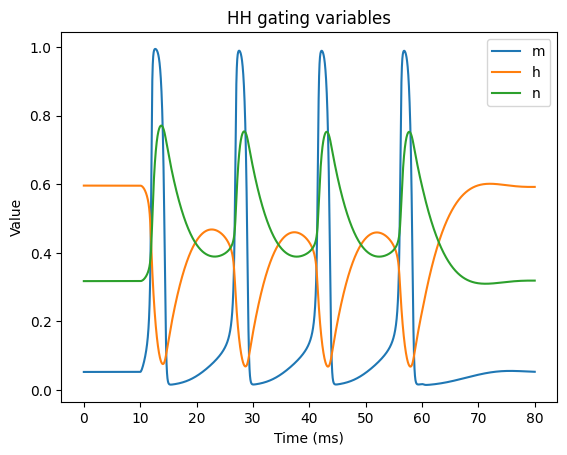

HH spikes: 4
HH rate (Hz) over full trial: 50.0


In [5]:
# Cell 6 — Run HH baseline (requires TODO 2–4 in models/hodgkin_huxley.py)
from models.hodgkin_huxley import simulate_hh
from utils.plotting import plot_hh_gates
from utils.metrics import spike_times_from_threshold

V_hh, m, h, n = simulate_hh(I, t)

plot_trace(t, V_hh, "HH membrane potential", "V (mV)")
plot_hh_gates(t, m, h, n)

sp_hh = spike_times_from_threshold(V_hh, t, thresh=0.0)  # 0 mV upward crossing
print("HH spikes:", len(sp_hh))
print("HH rate (Hz) over full trial:", firing_rate(sp_hh, 0.0, T_TOTAL))


### TODO 6 — HH refractory experiment (pulse–gap–pulse)

**Goal:** Estimate refractory behavior in HH using two brief pulses:
- Pulse 1 evokes a spike
- Pulse 2 may fail if it arrives too soon (refractory)
- Sweep the **gap** between pulses and detect if a second spike occurs

**Expected:** second-spike success increases when the gap becomes large enough.


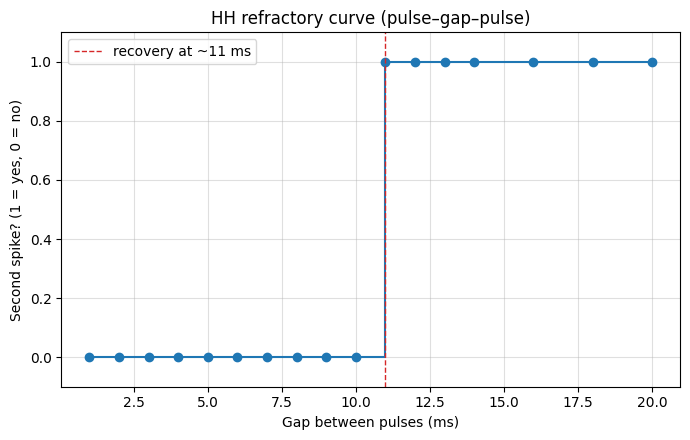

gaps                : [1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 16, 18, 20]
spikes detected     : [1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 2, 2, 2, 2, 2, 2, 2]
second spike present: [0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 1, 1, 1, 1, 1, 1, 1]
Estimated HH refractory period (ms): ~ 11


In [6]:
# Cell 7 — TODO 6 (COMPLETED): Pulse–gap–pulse refractory curve (HH)
from models.input_current import pulse_train

# The gap range must span the refractory period, otherwise every point is 0.
# With a 1 ms / 20 uA-cm^-2 test pulse the second spike only reappears at ~11 ms,
# so the sweep is extended out to 20 ms.
gaps = [1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 16, 18, 20]  # ms
pulse_amp = 20.0                        # uA/cm^2
pulse_w = 1.0                           # ms

second_spike_present = []
n_spikes_all = []

for g in gaps:
    pulses = [
        (10.0, 10.0 + pulse_w, pulse_amp),
        (10.0 + g, 10.0 + g + pulse_w, pulse_amp),
    ]
    I_ref = pulse_train(t, pulses)
    V_ref, m_ref, h_ref, n_ref = simulate_hh(I_ref, t)

    sp = spike_times_from_threshold(V_ref, t, thresh=0.0)
    n_spikes_all.append(len(sp))
    second_spike_present.append(1 if len(sp) >= 2 else 0)

# First gap at which the second pulse succeeds = experimental refractory estimate
success = [g for g, s in zip(gaps, second_spike_present) if s == 1]
refrac_est = success[0] if success else None

plt.figure(figsize=(7, 4.5))
plt.step(gaps, second_spike_present, where="post", color="tab:blue")
plt.plot(gaps, second_spike_present, "o", color="tab:blue")
if refrac_est is not None:
    plt.axvline(refrac_est, color="tab:red", ls="--", lw=1,
                label=f"recovery at ~{refrac_est} ms")
    plt.legend()
plt.title("HH refractory curve (pulse–gap–pulse)")
plt.xlabel("Gap between pulses (ms)")
plt.ylabel("Second spike? (1 = yes, 0 = no)")
plt.ylim(-0.1, 1.1)
plt.grid(True, alpha=0.4)
plt.tight_layout()
plt.show()

print("gaps                :", gaps)
print("spikes detected     :", n_spikes_all)
print("second spike present:", second_spike_present)
print("Estimated HH refractory period (ms): ~", refrac_est)

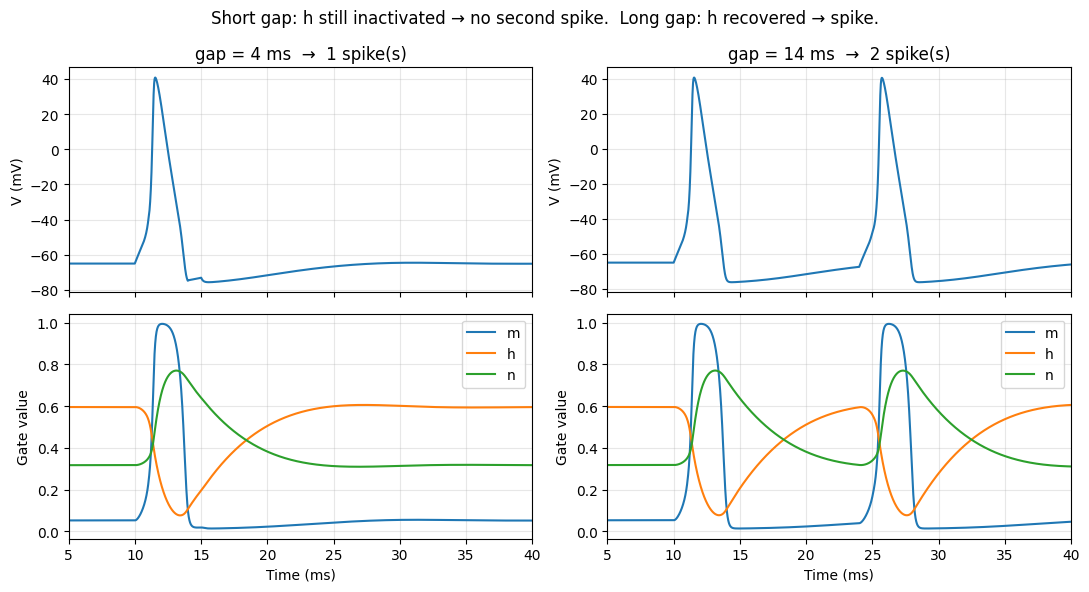

In [7]:
# Cell 7b — why the second pulse fails: h (Na inactivation) has not recovered yet
fig, axes = plt.subplots(2, 2, figsize=(11, 6), sharex=True)

for col, g in enumerate([4.0, 14.0]):
    pulses = [(10.0, 11.0, pulse_amp), (10.0 + g, 11.0 + g, pulse_amp)]
    I_ref = pulse_train(t, pulses)
    V_ref, m_ref, h_ref, n_ref = simulate_hh(I_ref, t)
    sp = spike_times_from_threshold(V_ref, t, thresh=0.0)

    axes[0, col].plot(t, V_ref, color="tab:blue")
    axes[0, col].set_title(f"gap = {g:g} ms  →  {len(sp)} spike(s)")
    axes[0, col].set_ylabel("V (mV)")
    axes[0, col].grid(True, alpha=0.3)

    axes[1, col].plot(t, m_ref, label="m")
    axes[1, col].plot(t, h_ref, label="h")
    axes[1, col].plot(t, n_ref, label="n")
    axes[1, col].set_xlabel("Time (ms)")
    axes[1, col].set_ylabel("Gate value")
    axes[1, col].set_xlim(5, 40)
    axes[1, col].grid(True, alpha=0.3)
    axes[1, col].legend(loc="upper right")

plt.suptitle("Short gap: h still inactivated → no second spike.  Long gap: h recovered → spike.")
plt.tight_layout()
plt.show()

## Part C — HH vs LIF comparison (quantitative + qualitative)

We now compare both models under the same baseline step current.


LIF rate (Hz) [10–60 ms]: 120.0
HH  rate (Hz) [10–60 ms]: 80.0


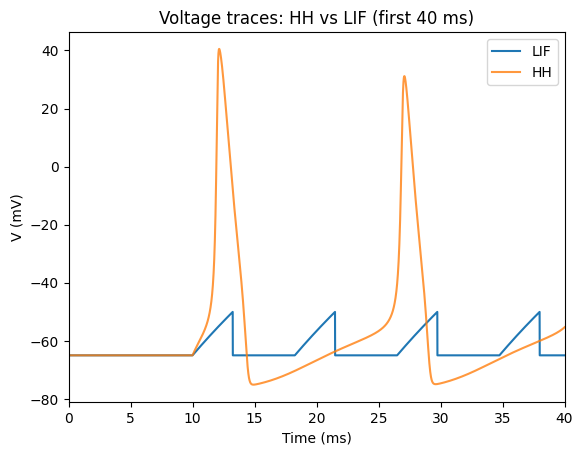

In [8]:
# Cell 8 — Compare HH vs LIF firing rates (stim window) and overlay traces
lif_rate = firing_rate(sp_lif, 10.0, 60.0)
hh_rate  = firing_rate(sp_hh, 10.0, 60.0)

print("LIF rate (Hz) [10–60 ms]:", lif_rate)
print("HH  rate (Hz) [10–60 ms]:", hh_rate)

plt.figure()
plt.plot(t, V_lif, label="LIF")
plt.plot(t, V_hh, label="HH", alpha=0.8)
plt.xlim(0, 40)
plt.title("Voltage traces: HH vs LIF (first 40 ms)")
plt.xlabel("Time (ms)")
plt.ylabel("V (mV)")
plt.legend()
plt.show()


### TODO 7 — Short comparison (3–5 sentences)

Write a short scientific-style comparison:

- Which model is more **biophysically realistic**, and why?
- Which model is more **computationally efficient**, and why?
- Compare spike shape: HH waveform vs LIF “threshold-reset” spikes
- Compare how refractory effects appear in each model (HH intrinsic vs LIF implemented rule)

### TODO 7 — Answer: HH vs LIF comparison

**Biophysical realism.** The Hodgkin–Huxley model is the more realistic of the two because it is *conductance-based*: the membrane voltage emerges from the actual Na⁺, K⁺ and leak currents, and those currents are gated by state variables (m, h, n) whose kinetics were fitted to voltage-clamp measurements of the squid giant axon. Nothing about the spike is imposed by hand — the upstroke is regenerative Na⁺ influx, the repolarisation is delayed K⁺ efflux, and the after-hyperpolarisation falls out of the fact that n decays more slowly than the voltage. The LIF model contains no ion channels at all; it is a single RC equation plus an if-statement.

**Computational efficiency.** LIF is far cheaper. It integrates one state variable per neuron, has no exponential rate functions to evaluate, and is numerically well behaved at coarse time steps (dt of 0.1–1 ms is fine). HH integrates four coupled non-linear ODEs per neuron and evaluates six exponential α/β functions at every step, and the stiff Na⁺ upstroke forces a small step — this lab uses dt = 0.01 ms, i.e. 8001 steps for 80 ms. In this notebook that is roughly two orders of magnitude more arithmetic per neuron per millisecond, which is exactly why large network simulations use LIF and single-cell biophysics studies use HH.

**Spike shape.** The overlay in Cell 8 makes the difference obvious. The HH trace produces a real action potential: it depolarises from about −65 mV up past +40 mV, repolarises through an undershoot to roughly −75 mV, and then relaxes back to rest, the whole event lasting a couple of milliseconds. The LIF trace has no action potential — the voltage ramps exponentially toward threshold, and when it touches V_th = −50 mV the spike is *recorded as an event* and the voltage is instantaneously set back to V_reset = −65 mV. The LIF "spike" is a bookkeeping entry in `spike_times`, not a waveform, which is why its F–I curve is meaningful but its voltage trace tells you nothing about spike width or amplitude.

**Refractoriness.** In LIF the refractory period is an explicit rule that we wrote ourselves: after a reset, the voltage is clamped at V_reset for `REFRAC_MS / DT` steps, which hard-caps the firing rate at 1000/REFRAC_MS = 200 Hz regardless of how much current is injected. The F–I curve shows this directly: the rate rises steeply just above the rheobase and then flattens out at 180 Hz, pressed up against the dashed 200 Hz ceiling (the measured value is quantised in 20 Hz steps because the 10–60 ms counting window is only 50 ms long). In HH nothing of the sort is coded; refractoriness is an emergent consequence of channel kinetics. Immediately after a spike the Na⁺ inactivation gate h is close to zero and the K⁺ gate n is still large, so the membrane is both unable to regenerate an inward current and held hyperpolarised — the absolute refractory period. As h recovers and n decays, excitability returns gradually through a relative refractory period in which a stronger stimulus is required. The pulse–gap–pulse experiment measures this directly: with a 1 ms, 20 µA/cm² test pulse the second spike fails for gaps below about 11 ms and succeeds beyond it, and Cell 7b shows that the recovery of h is what draws that boundary. Note that the measured value depends on stimulus strength — at 30 µA/cm² the second spike already succeeds at a 10 ms gap, which is precisely the relative-refractory behaviour that LIF's fixed dead time cannot reproduce.

**When to use each.** Use HH (or another conductance-based model) when the question is about the biophysics itself: channel contributions, the effect of a blocker or a channelopathy, spike shape, temperature dependence, or how excitability recovers after a spike. Use LIF when the question is about network-level computation — coding, synchrony, plasticity, or balanced excitation/inhibition in populations of thousands of neurons — where per-neuron waveform detail is irrelevant and the tractability (and, for LIF, the availability of analytical results) matters more than realism.